# Conceptos básicos de Regresión Logistica, Ecuación base y Aplicación a modelo simple de Predicción de Ventas

Observacion y aplicacion de tecnicas de entrenamiento de evaluacion y visualización de resultados de la regresión logistica

----------------------------------------

### Importacion de datos y librerias

In [1]:
# Importar libreriras a utilizar
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score
from sklearn.linear_model import LogisticRegression

# Importar archivo csv a utilizar
data = pd.read_csv('databses/general_data_.csv')
data

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,NumCompaniesWorked,Over18,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
0,51,No,Travel_Rarely,Sales,6,2,Life Sciences,1,1,Female,...,1.0,Y,11,8,0,1.0,6,1,0,0
1,31,Yes,Travel_Frequently,Research & Development,10,1,Life Sciences,1,2,Female,...,0.0,Y,23,8,1,6.0,3,5,1,4
2,32,No,Travel_Frequently,Research & Development,17,4,Other,1,3,Male,...,1.0,Y,15,8,3,5.0,2,5,0,3
3,38,No,Non-Travel,Research & Development,2,5,Life Sciences,1,4,Male,...,3.0,Y,11,8,3,13.0,5,8,7,5
4,32,No,Travel_Rarely,Research & Development,10,1,Medical,1,5,Male,...,4.0,Y,12,8,2,9.0,2,6,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4405,42,No,Travel_Rarely,Research & Development,5,4,Medical,1,4406,Female,...,3.0,Y,17,8,1,10.0,5,3,0,2
4406,29,No,Travel_Rarely,Research & Development,2,4,Medical,1,4407,Male,...,2.0,Y,15,8,0,10.0,2,3,0,2
4407,25,No,Travel_Rarely,Research & Development,25,2,Life Sciences,1,4408,Male,...,0.0,Y,20,8,0,5.0,4,4,1,2
4408,42,No,Travel_Rarely,Sales,18,2,Medical,1,4409,Male,...,0.0,Y,14,8,1,10.0,2,9,7,8


-------------------

### Exploratory Data Analysis

In [2]:
#Obtencion de los primeros resultados del DataFrame
data.head(5)

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,NumCompaniesWorked,Over18,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
0,51,No,Travel_Rarely,Sales,6,2,Life Sciences,1,1,Female,...,1.0,Y,11,8,0,1.0,6,1,0,0
1,31,Yes,Travel_Frequently,Research & Development,10,1,Life Sciences,1,2,Female,...,0.0,Y,23,8,1,6.0,3,5,1,4
2,32,No,Travel_Frequently,Research & Development,17,4,Other,1,3,Male,...,1.0,Y,15,8,3,5.0,2,5,0,3
3,38,No,Non-Travel,Research & Development,2,5,Life Sciences,1,4,Male,...,3.0,Y,11,8,3,13.0,5,8,7,5
4,32,No,Travel_Rarely,Research & Development,10,1,Medical,1,5,Male,...,4.0,Y,12,8,2,9.0,2,6,0,4


In [3]:
#Obtencion de los ultimos resultados del DataFrame
data.tail(5)

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,NumCompaniesWorked,Over18,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
4405,42,No,Travel_Rarely,Research & Development,5,4,Medical,1,4406,Female,...,3.0,Y,17,8,1,10.0,5,3,0,2
4406,29,No,Travel_Rarely,Research & Development,2,4,Medical,1,4407,Male,...,2.0,Y,15,8,0,10.0,2,3,0,2
4407,25,No,Travel_Rarely,Research & Development,25,2,Life Sciences,1,4408,Male,...,0.0,Y,20,8,0,5.0,4,4,1,2
4408,42,No,Travel_Rarely,Sales,18,2,Medical,1,4409,Male,...,0.0,Y,14,8,1,10.0,2,9,7,8
4409,40,No,Travel_Rarely,Research & Development,28,3,Medical,1,4410,Male,...,0.0,Y,12,8,0,NaN,6,21,3,9


In [4]:
#Obtencion de muestras del DataFrame
data.sample(5)

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,NumCompaniesWorked,Over18,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
3854,29,No,Travel_Rarely,Research & Development,20,1,Medical,1,3855,Female,...,9.0,Y,15,8,1,8.0,4,5,1,4
4302,40,No,Travel_Frequently,Research & Development,26,4,Medical,1,4303,Male,...,1.0,Y,12,8,1,20.0,2,20,2,13
1267,33,No,Travel_Frequently,Sales,29,4,Life Sciences,1,1268,Female,...,1.0,Y,14,8,1,15.0,2,15,8,12
1160,38,No,Travel_Frequently,Research & Development,1,4,Other,1,1161,Male,...,2.0,Y,19,8,0,10.0,2,8,7,7
1005,42,No,Travel_Rarely,Human Resources,1,3,Other,1,1006,Female,...,8.0,Y,13,8,1,7.0,3,5,0,4


In [5]:
#Obtener la estadistica básica del Dataframe
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4410.0,36.923810,9.133301,18.0,30.00,36.0,43.00,60.0
DistanceFromHome,4410.0,9.192517,8.105026,1.0,2.00,7.0,14.00,29.0
Education,4410.0,2.912925,1.023933,1.0,2.00,3.0,4.00,5.0
EmployeeCount,4410.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeID,4410.0,2205.500000,1273.201673,1.0,1103.25,2205.5,3307.75,4410.0
JobLevel,4410.0,2.063946,1.106689,1.0,1.00,2.0,3.00,5.0
MonthlyIncome,4410.0,65029.312925,47068.888559,10090.0,29110.00,49190.0,83800.00,199990.0
NumCompaniesWorked,4391.0,2.694830,2.498887,0.0,1.00,2.0,4.00,9.0
PercentSalaryHike,4410.0,15.209524,3.659108,11.0,12.00,14.0,18.00,25.0
StandardHours,4410.0,8.000000,0.000000,8.0,8.00,8.0,8.00,8.0


In [6]:
#Identificar si hay columnas con nulos
missing_values = data.isnull().sum().sum()

print(f'Existen', missing_values, 'valores nulos')

Existen 28 valores nulos


In [7]:
#Identificar las columnas especificas con dichos valores
missing_values_col = data.isnull().sum()
data.columns[missing_values_col.to_numpy().nonzero()]

Index(['NumCompaniesWorked', 'TotalWorkingYears'], dtype='object')

In [8]:
#Saber el tipo de dato que contiene cada columna
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   object 
 2   BusinessTravel           4410 non-null   object 
 3   Department               4410 non-null   object 
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   object 
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   object 
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   object 
 12  MaritalStatus            4410 non-null   object 
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked      

In [9]:
#Ubicar si la mayoria de columnas cuentan con datos unicos
data.nunique()

Age                          43
Attrition                     2
BusinessTravel                3
Department                    3
DistanceFromHome             29
Education                     5
EducationField                6
EmployeeCount                 1
EmployeeID                 4410
Gender                        2
JobLevel                      5
JobRole                       9
MaritalStatus                 3
MonthlyIncome              1349
NumCompaniesWorked           10
Over18                        1
PercentSalaryHike            15
StandardHours                 1
StockOptionLevel              4
TotalWorkingYears            40
TrainingTimesLastYear         7
YearsAtCompany               37
YearsSinceLastPromotion      16
YearsWithCurrManager         18
dtype: int64

--------------------

### Imputación de datos

In [10]:
#Se obtiene el promedio general
#Calculando el promedio de ambas varaiables con nulos
avg_numcompanieswork = int(data['NumCompaniesWorked'].mean())
num_total_working_years = int(data['TotalWorkingYears'].mean())

#Se realiza la imputacion de promedio a todos los registros nulos de estas columnas
data['NumCompaniesWorked'] = data['NumCompaniesWorked'].fillna(avg_numcompanieswork)
data['TotalWorkingYears'] = data['TotalWorkingYears'].fillna(num_total_working_years)

In [11]:
#Identificar si hay columnas con nulos
missing_values = data.isnull().sum().sum()

print(f'Existen', missing_values, 'valores nulos')

Existen 0 valores nulos


------------------------------------

### Análisis de correlación

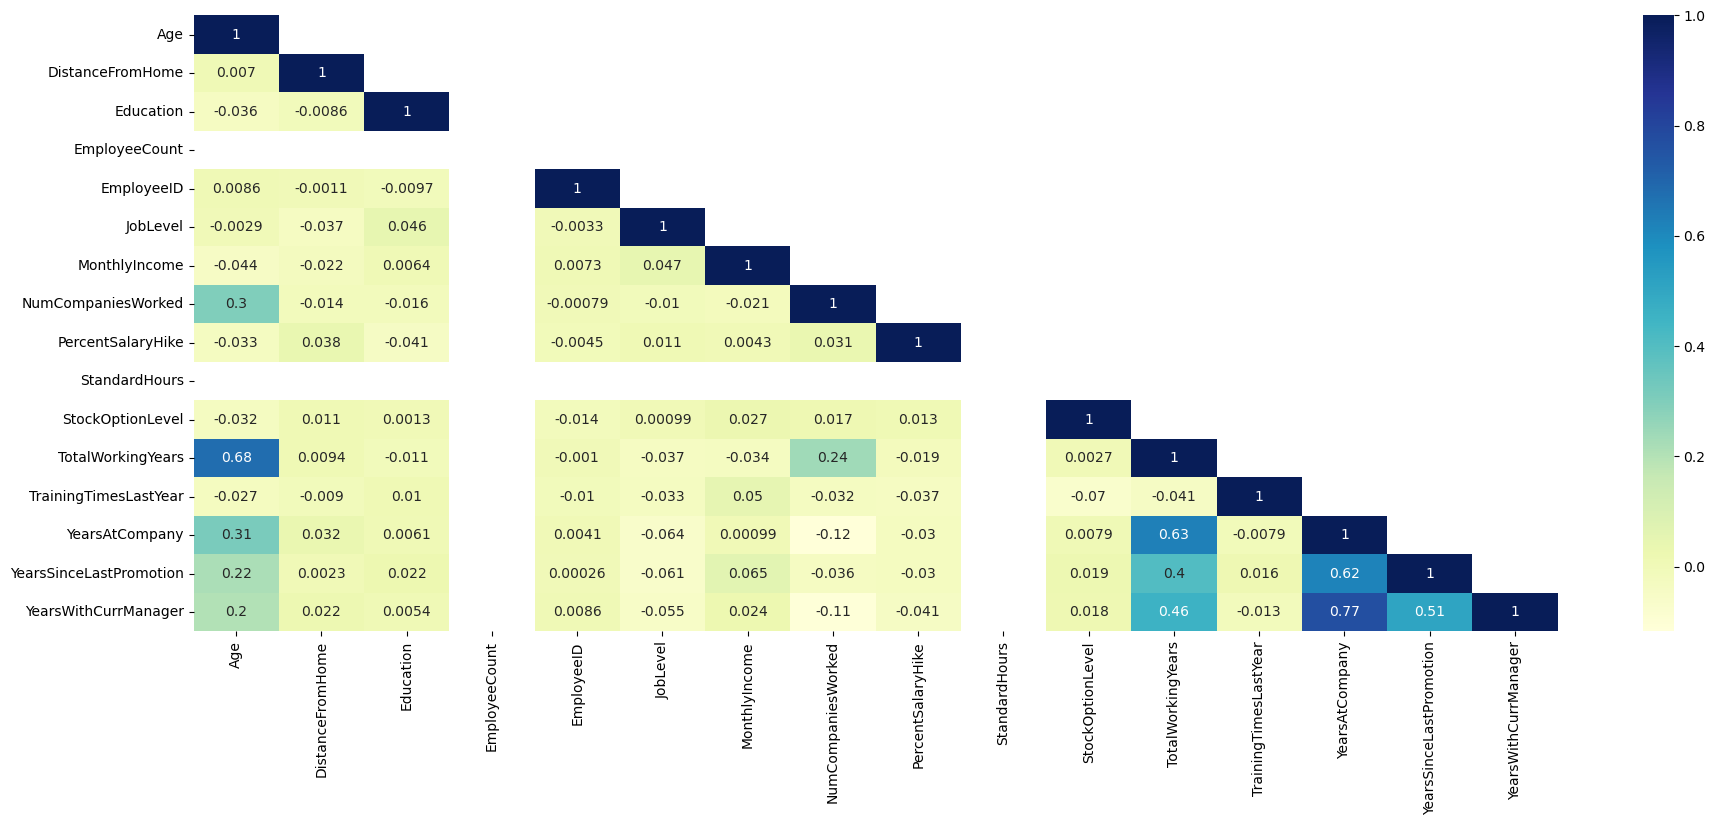

In [12]:
#Se realiza un mapa de calor para saber si hay variables con correlacion alta
plt.figure(figsize =(22,8))
corr_data = corr = data.corr(method = 'pearson', numeric_only= True)
data_lt = corr_data.where(np.tril(np.ones(corr_data.shape)).astype(bool))
hmap = sns.heatmap(data_lt,cmap = 'YlGnBu',annot = True)

-------------------------------

In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   object 
 2   BusinessTravel           4410 non-null   object 
 3   Department               4410 non-null   object 
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   object 
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   object 
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   object 
 12  MaritalStatus            4410 non-null   object 
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked      

### Feature Engineering

In [14]:
#Eliminacion de columnas a no utilizar
data.drop('EmployeeCount',axis=1, inplace = True)
data.drop('Over18',axis=1, inplace = True)
data.drop('StandardHours',axis= 1, inplace = True)
data.drop('EmployeeID',axis =1, inplace= True)

#Cambiar esta columna a tipo entero pero aparte llenar ese espacio por si tiene nulos
data['NumCompaniesWorked'] = data['NumCompaniesWorked'].fillna(0).astype(np.int64)
#Se imputa TotalWorkingYears como el promedio
num_total_working_years_mean = int(data['TotalWorkingYears'].mean())
#Imputar el promedio a todos los registros definidos como NaN
data['TotalWorkingYears'] = data['TotalWorkingYears'].fillna(num_total_working_years_mean)

#Transformación de tipo de dato 
data = data.astype({
    'BusinessTravel': 'category',
    'Department': 'category',
    'EducationField':'category',
    'Gender':'category',
    'JobRole':'category',
    'MaritalStatus':'category'
})

In [15]:
#Category - codes - automatico
data.Gender = data.Gender.astype('category').cat.codes
data.EducationField = data.EducationField.astype('category').cat.codes
data.BusinessTravel = data.BusinessTravel.astype('category').cat.codes
data.Department = data.Department.astype('category').cat.codes
data.MaritalStatus = data.MaritalStatus.astype('category').cat.codes
data.JobRole = data.JobRole.astype('category').cat.codes

In [16]:
#Balance de clases
#Obtener distintos valores
print(data['EducationField'].value_counts())
print('') 

print(data['BusinessTravel'].value_counts())
print('')

print(data['Department'].value_counts())
print('')

EducationField
1    1818
3    1392
2     477
5     396
4     246
0      81
Name: count, dtype: int64

BusinessTravel
2    3129
1     831
0     450
Name: count, dtype: int64

Department
1    2883
2    1338
0     189
Name: count, dtype: int64



In [17]:
#Cambiar manualmente la columna de 'attrition'
data['Attrition'] = data['Attrition'].replace({'Yes': 1,'No':0},regex = True)

C:\Users\USER\AppData\Local\Temp\ipykernel_20044\3336668630.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['Attrition'] = data['Attrition'].replace({'Yes': 1,'No':0},regex = True)


In [18]:
#Estandarizar la columna de Montly Income
scaler = StandardScaler()
data['MonthlyIncome'] = scaler.fit_transform(data[['MonthlyIncome']])

----------------------------------

### Data Split
- Entrenamiento, Evaluación y Prediccion de los resultados del modelo

In [19]:
#Se crea una copia del DataFrame original
data2 = data.copy()

In [ ]:
#Se crea primero el modelo en base a la columna a utilizar
x = data2.drop('Attrition', axis = 1)
y = data2['Attrition']

#Realizar el split de la data de 70% a 30%
x_train,x_test,y_train,y_test = train_test_split(x,y, test_size= 0.30, random_state= 1)
#Checar que el dataframe se dividio de forma correcta
print('{0:0.2f}% la data de esta en un  set de training'.format((len(x_train)/len(data2.index))*100))
print('{0:0.2f}% la data de esta en un  set de training'.format((len(x_test)/len(data2.index))*100))

70.00% la data de esta en un  set de training
30.00% la data de esta en un  set de training


----------------------------------------

### Modelo de Regresión Logistica

In [21]:
#Adapta el modelo de los x_train y y_train
model = LogisticRegression(solver = 'liblinear', class_weight='balanced')
model.fit(x_train,y_train)
#Hace la prediccion en x_test y la guarda en predict
y_predict = model.predict(x_test)

In [22]:
#Se construye un dataset con el valor original y prediccion
z = x_test.copy()
z['Attrition real']= y_test
z['Attrition prediccion'] = y_predict
z[['Attrition real','Attrition prediccion']].head(10)

,Attrition real,Attrition prediccion
2016,0,0
4118,0,1
219,0,0
4402,1,0
787,0,0
200,0,0
2539,0,0
3744,0,1
1891,0,1
3963,1,1


In [23]:
#Se genera el coeficiente de la ecuacion 
coef_data = pd.DataFrame(model.coef_)
coef_data.columns = x.columns
#Incluyendo el intercept
coef_data['intercept'] = model.intercept_
coef_data.T 

,0
Age,-0.026643
BusinessTravel,0.018681
Department,-0.284441
DistanceFromHome,0.001540
Education,-0.040473
EducationField,-0.079893
Gender,0.124802
JobLevel,-0.073882
JobRole,0.052852
MaritalStatus,0.624619


---------------------------------

### Análisis de Sensibilidad

In [24]:
#Se construye un regresor lineal para este análisis
regression_model = LinearRegression()

#Se genera un fit de la regresion con las variables de x & y
regression_model.fit(x_train,y_train)

LinearRegression()

In [25]:
regression_model.score(x_train,y_train)


0.09034124492301399

In [26]:
regression_model.score(x_test,y_test)

0.08041279400543622

In [27]:
#Se genera un dataframe donde se muestre el coef y su respectiva variable
coef_data = pd.concat([coef_data, pd.DataFrame({'Coeff': [regression_model.intercept_], 'Var':['Intercept']})],ignore_index= True)
for idx, col_name in enumerate(x_train.columns):
    coef_data = pd.concat([coef_data, pd.DataFrame({'Var': [col_name], 'Coeff':[regression_model.coef_[idx]]})],ignore_index= True)

data_coef = coef_data.dropna(subset=['Coeff','Var']).reset_index(drop =True)
data_coef[['Coeff','Var']]

,Coeff,Var
0,0.337762,Intercept
1,-0.004164,Age
2,-0.002299,BusinessTravel
3,-0.034782,Department
4,-0.000114,DistanceFromHome
5,-0.006084,Education
6,-0.010753,EducationField
7,0.016856,Gender
8,-0.003298,JobLevel
9,0.004969,JobRole


-----------------------

### Visualización de datos del modelo de clasificación

In [28]:
#Se realiza un metodo para este tipo de modelos de clasificacion 
#Devuelve la probabilidad
probs = model.predict_proba(x_test)[:, 1]

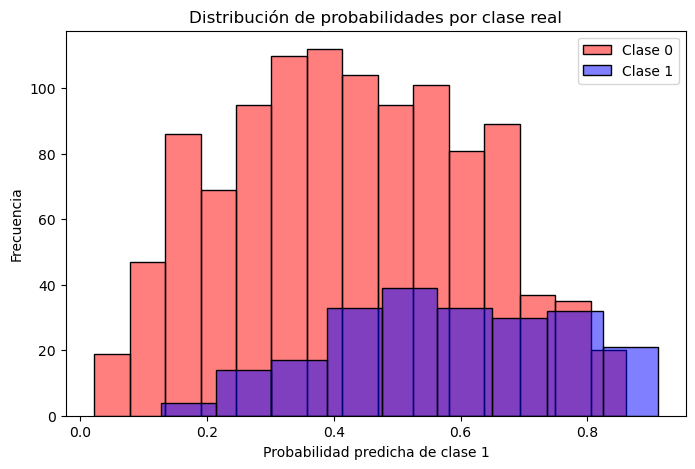

In [29]:
#En vez de hacer un gráfico de scatter se realiza uno de barras 
plt.figure(figsize=(8,5))
sns.histplot(probs[y_test == 0], color='red', label='Clase 0', alpha=0.5)
sns.histplot(probs[y_test == 1], color='blue', label='Clase 1', alpha=0.5)
plt.xlabel('Probabilidad predicha de clase 1')
plt.ylabel('Frecuencia')
plt.title('Distribución de probabilidades por clase real')
plt.legend()
plt.show()

------------------------------

### Matriz de Confusión y metricas

Text(0.5, 1.0, 'Matriz de Confusion')

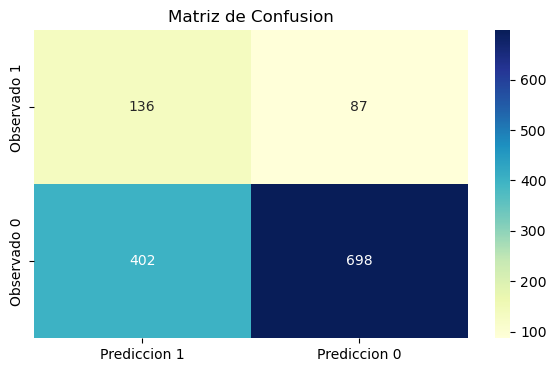

In [30]:
cm = metrics.confusion_matrix(y_test,y_predict,labels = [1,0])

data_cm = pd.DataFrame(cm, index = [i for i in ['Observado 1', 'Observado 0']],
                       columns = [i for i in ['Prediccion 1', 'Prediccion 0']])

plt.figure(figsize= (7,4))
sns.heatmap(data_cm, annot = True, cmap = 'YlGnBu', fmt = 'd').set_title('Matriz de Confusion')

In [31]:
#Medidas del modelo
y_pred = model.predict(x_test)
accuracy_score = accuracy_score(y_test,y_pred)
recall_score = recall_score(y_test,y_pred)
precision_score = precision_score(y_test,y_pred)
F1_score = f1_score(y_test,y_pred)

print('medidas del modelo')
print('----------------------------------')
print('Accuracy = {0:0.2f}'.format(accuracy_score))
print('Recall = {0:0.2f}'.format(recall_score))
print('Precision = {0:0.2f}'.format(precision_score))
print('F1 = {0:0.2f}'.format(F1_score))

medidas del modelo
----------------------------------
Accuracy = 0.63
Recall = 0.61
Precision = 0.25
F1 = 0.36
